In [11]:
import glob
import os

swot_dir = "/data1/data/obs/level3/SWOT/V-3/"

fichiers = sorted(glob.glob(f"{swot_dir}/*_20240210T*.nc"))
print(len(fichiers), "fichiers ce jour")
print(os.path.basename(fichiers[0]))

29 fichiers ce jour
SWOT_L3_LR_SSH_Expert_010_448_20240209T233621_20240210T002747_v3.0.nc


In [19]:
import xarray as xr

ds = xr.open_dataset('/data1/data/obs/level3/SWOT/V-3/SWOT_L3_LR_SSH_Expert_010_451_20240210T021041_20240210T030208_v3.0.nc')
print(ds.dims)
print(ds["time"].values[:3])
print(ds["time"].values[-3:])

FrozenMappingWarningOnValuesAccess({'num_lines': 9860, 'num_pixels': 69, 'num_nadir': 1208})
['2024-02-10T02:10:41.984999936' '2024-02-10T02:10:42.162716928'
 '2024-02-10T02:10:42.476888576']
['2024-02-10T03:02:07.655563392' '2024-02-10T03:02:07.968643840'
 '2024-02-10T03:02:08.281768576']


In [20]:
# les variables qui utilisent la dimension num_nadir
print([v for v in ds.data_vars if "num_nadir" in ds[v].dims])

['i_num_line', 'i_num_pixel']


In [21]:
print(ds["i_num_line"])

<xarray.DataArray 'i_num_line' (num_nadir: 1208)> Size: 2kB
[1208 values with dtype=int16]
Dimensions without coordinates: num_nadir
Attributes:
    comment:    alongtrack indice of the nearest karin pixel from the nadir data
    long_name:  alongtrack indice of the nearest karin pixel from the nadir data
    units:      count


In [22]:
print(ds["i_num_pixel"])

<xarray.DataArray 'i_num_pixel' (num_nadir: 1208)> Size: 1kB
[1208 values with dtype=int8]
Dimensions without coordinates: num_nadir
Attributes:
    comment:    acrosstrack indice of the nearest karin pixel from the nadir ...
    long_name:  acrosstrack indice of the nearest karin pixel from the nadir ...
    units:      count


In [23]:
import numpy as np

lignes = ds["i_num_line"].values
pixels = ds["i_num_pixel"].values

ssh = ds["ssha_unfiltered"].values      # forme (num_lines, num_pixels)
lon = ds["longitude"].values
lat = ds["latitude"].values

ssh_nadir = ssh[lignes, pixels]          # une valeur par point nadir
lon_nadir = lon[lignes, pixels]
lat_nadir = lat[lignes, pixels]

print("pixels utilisés :", np.unique(pixels))
print("valeurs valides :", np.isfinite(ssh_nadir).sum(), "sur", len(ssh_nadir))
print("exemples :", ssh_nadir[:10])

pixels utilisés : [34]
valeurs valides : 1208 sur 1208
exemples : [ 0.021  0.028  0.028  0.042  0.027  0.013  0.021  0.032  0.01  -0.013]


In [24]:
ssh_corr = (ds["ssha_unfiltered"] - ds["LongWavelenghtError_cnst_swot_karin"]
            - ds["LongWavelenghtError_lin_swot_karin"]).values
print("ssh_corr valides au nadir :", np.isfinite(ssh_corr[lignes, pixels]).sum())

ssh_corr valides au nadir : 1208


129 points nadir SWOT dans la boîte
129 points swon CMEMS dans la boîte


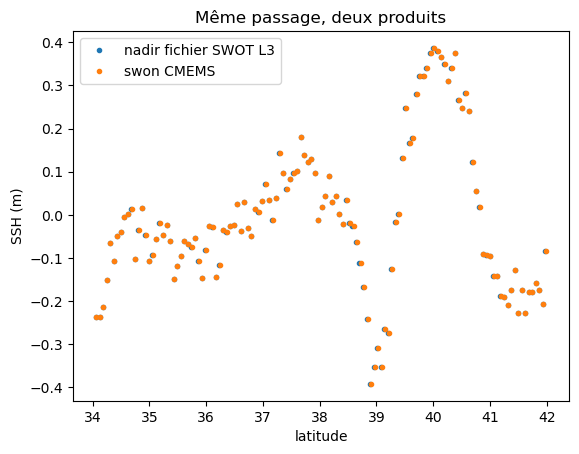

In [25]:
import glob
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

cmems_dir = "/home/nora/projects/NeurOST/input_data/cmems_sla"

# --- nadir du fichier SWOT, dans la boîte GS ---
temps_nadir = ds["time"].values[lignes]
lon_n = (lon_nadir + 180) % 360 - 180
dans_boite_n = (lon_n > -65) & (lon_n < -55) & (lat_nadir > 34) & (lat_nadir < 42)

# --- swon CMEMS : les deux jours, car le passage traverse minuit ---
t_debut = ds["time"].values[0]
t_fin = ds["time"].values[-1]

lat_c, ssh_c = [], []
for jour in ["20240209", "20240210"]:
    f = sorted(glob.glob(f"{cmems_dir}/swon/dt_global_swon_phy_l3_1hz_{jour}_*.nc"))[-1]
    sw = xr.open_dataset(f)
    # TODO 1 : garder les points swon entre t_debut et t_fin
    #          (sw.time.values >= t_debut) & ...
    meme_passage = (sw.time.values >= t_debut) & (sw.time.values <= t_fin)

    lo = (sw.longitude.values + 180) % 360 - 180
    la = sw.latitude.values

    # TODO 2 : ET dans la boîte GS (même logique que dans_boite_n)
    garde = meme_passage & (lo > -65) & (lo < -55) & (la > 34) & (la < 42)

    lat_c.extend(la[garde])
    ssh_c.extend(sw.sla_unfiltered.values[garde])
    sw.close()

print(dans_boite_n.sum(), "points nadir SWOT dans la boîte")
print(len(lat_c), "points swon CMEMS dans la boîte")

# --- les deux profils le long de la trace ---
plt.plot(lat_nadir[dans_boite_n], ssh_nadir[dans_boite_n], ".", label="nadir fichier SWOT L3")
plt.plot(lat_c, ssh_c, ".", label="swon CMEMS")
plt.xlabel("latitude")
plt.ylabel("SSH (m)")
plt.legend()
plt.title("Même passage, deux produits")
plt.show()

In [18]:
for f in fichiers:
    d = xr.open_dataset(f)
    lo = (d.longitude.values + 180) % 360 - 180
    la = d.latitude.values
    n = ((lo > -65) & (lo < -55) & (la > 34) & (la < 42)).sum()
    if n > 0:
        print(os.path.basename(f), n, "points dans la boîte")
    d.close()

SWOT_L3_LR_SSH_Expert_010_451_20240210T021041_20240210T030208_v3.0.nc 31399 points dans la boîte
SWOT_L3_LR_SSH_Expert_010_464_20240210T131930_20240210T141057_v3.0.nc 31399 points dans la boîte


In [32]:
import glob
import re
import numpy as np
import pandas as pd
import xarray as xr

ssh_corr = (ds["ssha_unfiltered"] - ds["LongWavelenghtError_cnst_swot_karin"]
            - ds["LongWavelenghtError_lin_swot_karin"]).values

def infos_passage(fichier, boite):
    """Renvoie un dict décrivant le passage dans la boîte, ou None s'il ne la traverse pas."""
    lon_min, lon_max, lat_min, lat_max = boite

    # TODO 1 : cycle et passe depuis le nom du fichier
    # indice : re.search(r"_(\d{3})_(\d{3})_\d{8}T", fichier) -> groupes 1 et 2
    m = re.search(r"_(\d{3})_(\d{3})_\d{8}T", fichier)
    cycle = int(m.group(1))     # "010" -> 10
    passe = int(m.group(2))     # "011" -> 11

    ds = xr.open_dataset(fichier)
    lon = (ds["longitude"].values + 180) % 360 - 180   # 0-360 -> -180-180
    lat = ds["latitude"].values
    ssh = (ds["ssha_unfiltered"].values
           - ds["LongWavelenghtError_cnst_swot_karin"].values
           - ds["LongWavelenghtError_lin_swot_karin"].values)                         # (num_lines, num_pixels)
    temps = ds["time"].values                           # (num_lines,)

    # TODO 2 : masque 2D "dans la boîte ET ssh valide"
    dans_boite = ((lon > lon_min) & (lon < lon_max) &
              (lat > lat_min) & (lat < lat_max) &
              np.isfinite(ssh))

    # TODO 3 : retirer les cases nadir de ce masque (elles serviront d'entrée)
    lignes = ds["i_num_line"].values
    pixels = ds["i_num_pixel"].values
    est_nadir = np.zeros(ssh.shape, dtype=bool)
    est_nadir[lignes, pixels] = True
    karin_ok = dans_boite & ~est_nadir         # dans_boite et pas nadir
    nadir_ok = dans_boite & est_nadir        # dans_boite et nadir

    # si pas de KaRIn dans la boîte, on ignore ce passage
    if karin_ok.sum() == 0:
        ds.close()
        return None

    # TODO 4 : lignes (temps) où il y a au moins un point valide
    # indice : karin_ok.any(axis=1)
    lignes_ok = karin_ok.any(axis=1)

    infos = {
        "fichier": fichier,
        "cycle": cycle,
        "passe": passe,
        "t_debut": temps[lignes_ok].min(),
        "t_fin": temps[lignes_ok].max(),
        "n_nadir": int(nadir_ok.sum()),
        "n_karin": int(karin_ok.sum()),
    }
    ds.close()
    return infos

In [33]:
boite_gs = (-65, -55, 34, 42)
fichiers = sorted(glob.glob(f"{swot_dir}/*_2024021[0-2]T*.nc"))

liste = []
for f in fichiers:
    infos = infos_passage(f, boite_gs)
    if infos is not None:
        liste.append(infos)

passages = pd.DataFrame(liste)
print(len(fichiers), "fichiers lus ->", len(passages), "passages dans la boîte")
print(passages)

85 fichiers lus -> 6 passages dans la boîte
                                             fichier  cycle  passe  \
0  /data1/data/obs/level3/SWOT/V-3/SWOT_L3_LR_SSH...     10    451   
1  /data1/data/obs/level3/SWOT/V-3/SWOT_L3_LR_SSH...     10    464   
2  /data1/data/obs/level3/SWOT/V-3/SWOT_L3_LR_SSH...     10    479   
3  /data1/data/obs/level3/SWOT/V-3/SWOT_L3_LR_SSH...     10    492   
4  /data1/data/obs/level3/SWOT/V-3/SWOT_L3_LR_SSH...     10    507   
5  /data1/data/obs/level3/SWOT/V-3/SWOT_L3_LR_SSH...     10    520   

                        t_debut                         t_fin  n_nadir  \
0 2024-02-10 02:46:21.517138304 2024-02-10 02:48:47.468315904      129   
1 2024-02-10 13:32:52.227159680 2024-02-10 13:35:18.474253056      129   
2 2024-02-11 02:46:52.733697408 2024-02-11 02:49:18.687598464      125   
3 2024-02-11 13:33:23.421996416 2024-02-11 13:35:49.669814528      127   
4 2024-02-12 02:47:23.945597056 2024-02-12 02:49:49.896483456      129   
5 2024-02-12 13:34:50

In [35]:
for f in fichiers:
    if "20240209T23" in f:
        print(f.split("/")[-1])
        print(infos_passage(f, boite_gs))

SWOT_L3_LR_SSH_Expert_010_448_20240209T233621_20240210T002747_v3.0.nc
None


In [36]:
f = [f for f in fichiers if "_448_" in f][0]
ds = xr.open_dataset(f)
lignes = ds["i_num_line"].values
pixels = ds["i_num_pixel"].values
lon_n = (ds["longitude"].values[lignes, pixels] + 180) % 360 - 180
lat_n = ds["latitude"].values[lignes, pixels]

bande = (lat_n > 34) & (lat_n < 42)
print("points nadir entre 34 et 42°N :", bande.sum())
print("longitudes :", lon_n[bande].min(), "->", lon_n[bande].max())

points nadir entre 34 et 42°N : 129
longitudes : 145.42633 -> 147.684511
